# Formative 2: Modeling Human Activity States with a Hidden Markov Model
HMM (Gaussian emissions, diagonal covariance) implemented **from scratch with NumPy**: Viterbi decoding + Baum-Welch training with a log-likelihood convergence check.

**Individual submission.** Data layout:
```
data/            <- training clips  (<activity>_<name>_<nn>.csv)
data_test/       <- OPTIONAL unseen test clips from a new session (same naming, all 4 activities)
```
Each CSV needs a time column (`seconds_elapsed`, `timestamp` or `time`) and `ax, ay, az, gx, gy, gz`. If `data_test/` is missing, the notebook falls back to holding out the last 2 clips of each activity and prints a warning (weaker evidence of generalisation, because those clips come from the same recordings).

In [1]:
import os, glob, re, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
rng = np.random.default_rng(42)

# ---------------- CONFIG ----------------
DATA_DIR   = 'data'
ACTIVITIES = ['standing', 'walking', 'jumping', 'still']
TARGET_FS  = 50          # Hz - all phones are resampled to this common rate
WINDOW_SEC = 2.0         # window length (s)  -> 100 samples at 50 Hz
OVERLAP    = 0.5         # 50% overlap
TRIM_SEC   = 0.5         # drop start/end of every recording (hand-on/hand-off motion)
TEST_DIR   = 'data_test'  # optional folder with unseen test clips (new session)
TEST_FILES_PER_ACTIVITY = 2   # fallback only: last N clips per activity held out if TEST_DIR is absent
DEVICE = 'iPhone 11 Pro, Sensor Logger (uncalibrated accelerometer + gyroscope, ~100 Hz native)'
# ----------------------------------------
WIN  = int(WINDOW_SEC * TARGET_FS)
STEP = int(WIN * (1 - OVERLAP))
COLS = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']
print(f'Window = {WIN} samples ({WINDOW_SEC}s @ {TARGET_FS} Hz), step = {STEP} samples')

Window = 100 samples (2.0s @ 50 Hz), step = 50 samples


In [2]:
# Colab only: mount Drive and unzip data_split.zip (contains data/ and data_test/). Skipped elsewhere.
try:
    from google.colab import drive
    import shutil, zipfile
    drive.mount('/content/drive')
    for d in ['data', 'data_test']: shutil.rmtree(d, ignore_errors=True)   # avoid stale/leaked files
    zipfile.ZipFile('/content/drive/MyDrive/data_split.zip').extractall('.')
except ImportError:
    pass
print({d: len(os.listdir(d)) for d in ['data', 'data_test'] if os.path.isdir(d)})

Mounted at /content/drive
{'data': 38, 'data_test': 29}


## 1. Data loading, timestamp cleaning and sampling-rate harmonisation

In [3]:
def merge_sensor_logger(acc_csv, gyro_csv, out_csv):
    """Merge Sensor Logger's Accelerometer.csv + Gyroscope.csv into one file with ax..gz."""
    a = pd.read_csv(acc_csv).rename(columns={'x':'ax','y':'ay','z':'az'})
    g = pd.read_csv(gyro_csv).rename(columns={'x':'gx','y':'gy','z':'gz'})
    key = 'seconds_elapsed' if 'seconds_elapsed' in a.columns else 'time'
    m = pd.merge_asof(a.sort_values(key), g[[key,'gx','gy','gz']].sort_values(key), on=key, direction='nearest')
    m[['seconds_elapsed' if key=='seconds_elapsed' else key,'ax','ay','az','gx','gy','gz']].to_csv(out_csv, index=False)

def to_seconds(t):
    t = np.asarray(t, float)
    if t.max() > 1e17:   t = t / 1e9     # ns epoch
    elif t.max() > 1e14: t = t / 1e6     # us epoch
    elif t.max() > 1e11: t = t / 1e3     # ms epoch
    return t - t[0]

def load_recording(path):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    tcol = next(c for c in ['seconds_elapsed', 'timestamp', 'time'] if c in df.columns)
    df = df.dropna(subset=[tcol] + COLS).sort_values(tcol)
    df = df.drop_duplicates(subset=tcol)
    t = to_seconds(df[tcol].values)
    native_fs = 1.0 / np.median(np.diff(t))
    # Resample every signal onto a common uniform grid at TARGET_FS (linear interpolation)
    grid = np.arange(0, t[-1], 1 / TARGET_FS)
    X = np.column_stack([np.interp(grid, t, df[c].values) for c in COLS])
    k = int(TRIM_SEC * TARGET_FS)
    return X[k:len(X) - k], native_fs, t[-1]

def load_dir(folder):
    recs = []
    for path in sorted(glob.glob(os.path.join(folder, '*.csv'))):
        name = os.path.basename(path)
        act = next((a for a in ACTIVITIES if name.lower().startswith(a)), None)
        if act is None: continue
        X, fs, dur = load_recording(path)
        if len(X) >= WIN:
            recs.append(dict(file=name, activity=act, raw=X, native_fs=fs, duration=dur))
        else:
            print('Skipped (too short):', name)
    return recs

records = load_dir(DATA_DIR)
external_test = load_dir(TEST_DIR) if os.path.isdir(TEST_DIR) else []
if not records:
    found = glob.glob('**/*.csv', recursive=True)
    raise FileNotFoundError(f"No clips found in '{os.path.abspath(DATA_DIR)}'. Working dir: {os.getcwd()}. "
                            f"CSV files found elsewhere: {found[:5]} - set DATA_DIR to the folder that directly contains "
                            "standing_*.csv, walking_*.csv, jumping_*.csv, still_*.csv")
meta = pd.DataFrame([{k: r[k] for k in ['file','activity','native_fs','duration']} for r in records])
print(f'Device: {DEVICE}')
print(f'{len(meta)} training clips | {len(external_test)} external test clips')
display(meta.groupby('activity').agg(files=('file','count'), clip_seconds=('duration','sum'),
                                     native_fs_hz=('native_fs','mean')).round(1))

Device: iPhone 11 Pro, Sensor Logger (uncalibrated accelerometer + gyroscope, ~100 Hz native)
38 training clips | 29 external test clips


,files,clip_seconds,native_fs_hz
activity,,,
jumping,7,41.9,100.4
standing,9,53.9,100.4
still,12,71.9,100.4
walking,10,59.9,100.4


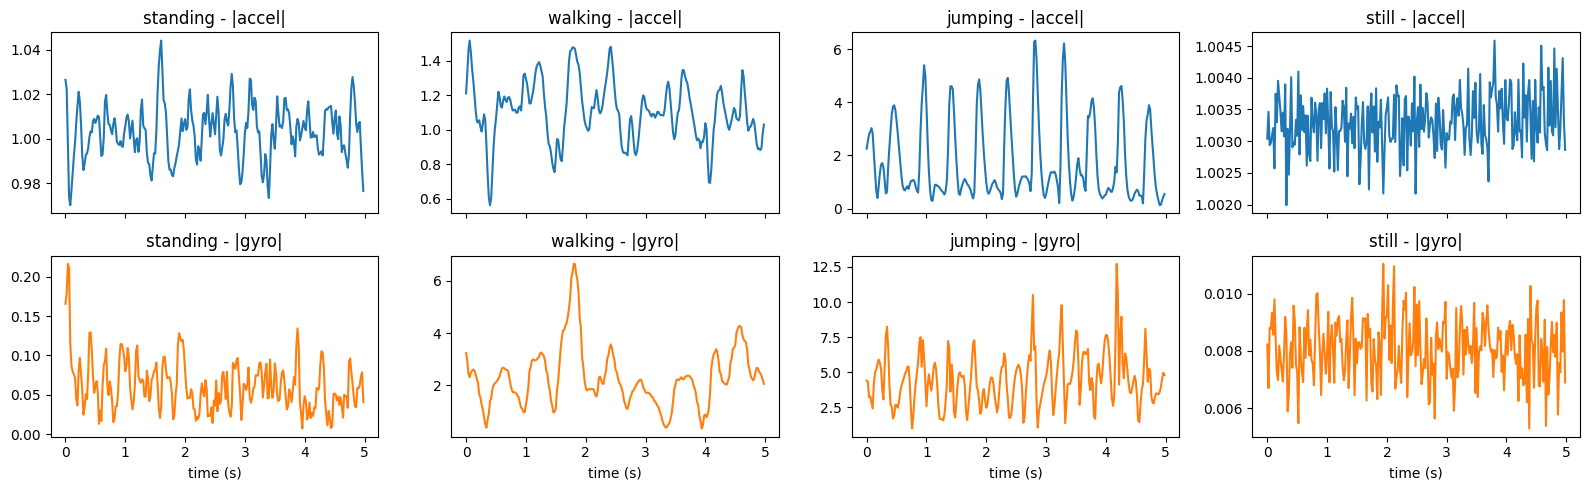

In [4]:
# Raw-data visualisation: one example per activity (accelerometer magnitude + gyroscope magnitude)
fig, axes = plt.subplots(2, 4, figsize=(16, 5), sharex=True)
for j, a in enumerate(ACTIVITIES):
    r = next(r for r in records if r['activity'] == a)
    tt = np.arange(len(r['raw'])) / TARGET_FS
    axes[0, j].plot(tt, np.linalg.norm(r['raw'][:, :3], axis=1)); axes[0, j].set_title(f'{a} - |accel|')
    axes[1, j].plot(tt, np.linalg.norm(r['raw'][:, 3:], axis=1), color='tab:orange'); axes[1, j].set_title(f'{a} - |gyro|')
    axes[1, j].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

## 2. Windowing and feature extraction
- **Window size:** 2 s at 50 Hz = 100 samples. Walking and jumping occur at roughly 1-3 Hz, so a 2 s window holds 2-6 full cycles and gives a frequency resolution of 0.5 Hz; 50% overlap increases the number of observations without discarding information at window edges.
- **Sampling rate:** the phone logs at about 100 Hz; each recording is linearly interpolated onto a uniform 50 Hz grid (this also corrects small timestamp jitter), so every window covers exactly 2 s. 50 Hz is below or equal to the native rate of all modern phones and well above the Nyquist requirement for human motion (<25 Hz).
- **Time-domain features:** mean, standard deviation, RMS of the accel/gyro magnitude (intensity/variability separates still/standing from walking/jumping), signal magnitude area (SMA, overall activity energy), correlation between accelerometer axes (coordination of motion across axes).
- **Frequency-domain features (FFT):** dominant frequency (gait/jump cadence), spectral energy (power of periodic motion) and spectral entropy (periodic vs noise-like signal).
- **Normalisation:** z-score, fitted on training windows only. Gaussian emissions assume comparable scales, and features such as spectral energy and frequency differ by orders of magnitude.

In [5]:
def spectral(x, fs):
    x = x - x.mean()
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2
    f = np.fft.rfftfreq(len(x), 1 / fs)
    Pn = P[1:] / (P[1:].sum() + 1e-12)
    dom = f[1:][np.argmax(P[1:])]
    return dom, P.sum() / len(x), -(Pn * np.log(Pn + 1e-12)).sum()

def window_features(w):
    acc, gyr = w[:, :3], w[:, 3:]
    am, gm = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    f = {}
    for nm, m in [('acc', am), ('gyr', gm)]:
        d, e, h = spectral(m, TARGET_FS)
        f.update({f'{nm}_mean': m.mean(), f'{nm}_std': m.std(), f'{nm}_rms': np.sqrt((m**2).mean()),
                  f'{nm}_dom_freq': d, f'{nm}_spec_energy': e, f'{nm}_spec_entropy': h})
    f['acc_sma'] = np.abs(acc).sum(axis=1).mean()
    f['gyr_sma'] = np.abs(gyr).sum(axis=1).mean()
    C = np.nan_to_num(np.corrcoef(acc.T))
    f.update({'corr_xy': C[0, 1], 'corr_xz': C[0, 2], 'corr_yz': C[1, 2]})
    return f

def featurize(raw):
    rows = [window_features(raw[s:s + WIN]) for s in range(0, len(raw) - WIN + 1, STEP)]
    return pd.DataFrame(rows)

for r in records + external_test:
    r['F'] = featurize(r['raw'])
FEATURES = list(records[0]['F'].columns)
print(len(FEATURES), 'features:', FEATURES)
print('Total windows:', sum(len(r['F']) for r in records))

17 features: ['acc_mean', 'acc_std', 'acc_rms', 'acc_dom_freq', 'acc_spec_energy', 'acc_spec_entropy', 'gyr_mean', 'gyr_std', 'gyr_rms', 'gyr_dom_freq', 'gyr_spec_energy', 'gyr_spec_entropy', 'acc_sma', 'gyr_sma', 'corr_xy', 'corr_xz', 'corr_yz']
Total windows: 152


## 3. Train / unseen-test split and session construction
No window from a test clip is ever used in training. Best practice: record a **new session** (different time/place/pace), save its clips in `data_test/`, and describe this in the report.

Because each recording contains a single activity, recordings are stitched into **sessions** (one clip per activity, random order) so the HMM can learn transitions between activities. Test clips are each used exactly once, so the sample counts in the results table are the true number of unseen windows. The learned `A` therefore reflects this recording protocol: strong self-transitions with small, roughly uniform switching probabilities.

In [6]:
if external_test and {r['activity'] for r in external_test} == set(ACTIVITIES):
    train_records, test_records = records, external_test
    print('Using external unseen test set from', TEST_DIR)
else:
    test_records, train_records = [], []
    for a in ACTIVITIES:
        rs = [r for r in records if r['activity'] == a]          # sorted by file name
        test_records  += rs[-TEST_FILES_PER_ACTIVITY:]
        train_records += rs[:-TEST_FILES_PER_ACTIVITY]
    print('WARNING: no complete external test set found - holding out the last '
          f'{TEST_FILES_PER_ACTIVITY} clips per activity (same recordings as training; optimistic estimate).')
print('train files:', len(train_records), '| test files:', len(test_records))
print('test files :', [r['file'] for r in test_records])

# z-score normalisation fitted on TRAIN windows only
train_all = pd.concat([r['F'] for r in train_records]).values
MU, SD = train_all.mean(0), train_all.std(0) + 1e-8
norm = lambda F: (F.values - MU) / SD

def make_sessions(recs, n_sessions, seed, cycle=True):
    rg = np.random.default_rng(seed)
    by = {a: [r for r in recs if r['activity'] == a] for a in ACTIVITIES}
    orders = {a: rg.permutation(len(by[a])) for a in ACTIVITIES}
    seqs, labels, names = [], [], []
    for k in range(n_sessions):
        X, y, n = [], [], []
        for a in rg.permutation(len(ACTIVITIES)):
            act = ACTIVITIES[a]
            if not cycle and k >= len(by[act]): continue   # each clip used exactly once
            r = by[act][orders[act][k % len(by[act])]]
            X.append(norm(r['F'])); y += [a] * len(r['F']); n.append(r['file'])
        if X: seqs.append(np.vstack(X)); labels.append(np.array(y)); names.append(n)
    return seqs, labels, names

max_tr = max(sum(r['activity'] == a for r in train_records) for a in ACTIVITIES)
max_te = max(sum(r['activity'] == a for r in test_records) for a in ACTIVITIES)
train_seqs, train_lab, _          = make_sessions(train_records, 3 * max_tr, seed=1)
test_seqs,  test_lab,  test_names = make_sessions(test_records,  max_te,     seed=2, cycle=False)
print('train sessions:', len(train_seqs), '| test sessions:', len(test_seqs))

Using external unseen test set from data_test
train files: 38 | test files: 29
test files : ['jumping_bianca_07.csv', 'jumping_bianca_08.csv', 'jumping_bianca_09.csv', 'jumping_bianca_10.csv', 'jumping_bianca_11.csv', 'jumping_bianca_12.csv', 'jumping_bianca_13.csv', 'jumping_bianca_14.csv', 'jumping_bianca_15.csv', 'standing_bianca_09.csv', 'standing_bianca_10.csv', 'standing_bianca_11.csv', 'standing_bianca_12.csv', 'standing_bianca_13.csv', 'standing_bianca_14.csv', 'standing_bianca_15.csv', 'still_bianca_12.csv', 'still_bianca_13.csv', 'still_bianca_14.csv', 'still_bianca_15.csv', 'walking_bianca_10.csv', 'walking_bianca_11.csv', 'walking_bianca_12.csv', 'walking_bianca_13.csv', 'walking_bianca_14.csv', 'walking_bianca_15.csv', 'walking_bianca_16.csv', 'walking_bianca_17.csv', 'walking_bianca_18.csv']
train sessions: 36 | test sessions: 9


## 4. HMM implementation (NumPy only)
**Components:** hidden states Z = {standing, walking, jumping, still}; observations X = z-scored feature vectors per window; `A` transition matrix; `B` Gaussian (diagonal) emissions; `pi` initial distribution.

**Algorithms:** *Viterbi* gives the single most likely activity sequence (what we evaluate with sensitivity/specificity/accuracy). *Baum-Welch (EM)* re-estimates `pi`, `A`, and emission parameters to maximise the likelihood, and stops when the relative change in total log-likelihood falls below `tol`. All computations are in the log domain for numerical stability. Parameters are initialised from labelled training windows so each hidden state aligns with one activity.

In [7]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return out.squeeze(axis) if axis is not None else out.item()

class GaussianHMM:
    def __init__(self, n_states, n_features, var_floor=1e-2):
        self.K, self.D, self.var_floor = n_states, n_features, var_floor
        self.pi = np.full(n_states, 1 / n_states)
        self.A  = np.full((n_states, n_states), 1 / n_states)
        self.mu = np.zeros((n_states, n_features)); self.var = np.ones((n_states, n_features))
        self.ll_history = []

    def init_supervised(self, seqs, labels, smooth=1.0):
        X, y = np.vstack(seqs), np.concatenate(labels)
        for k in range(self.K):
            self.mu[k]  = X[y == k].mean(0)
            self.var[k] = X[y == k].var(0) + self.var_floor
        A = np.full((self.K, self.K), smooth); pi = np.full(self.K, smooth)
        for l in labels:
            pi[l[0]] += 1
            for i, j in zip(l[:-1], l[1:]): A[i, j] += 1
        self.A, self.pi = A / A.sum(1, keepdims=True), pi / pi.sum()

    def log_emission(self, X):                     # (T, K)
        return -0.5 * (np.log(2 * np.pi * self.var).sum(1)[None, :]
                       + (((X[:, None, :] - self.mu[None]) ** 2) / self.var[None]).sum(2))

    def forward(self, logB):
        T = len(logB); logA = np.log(np.maximum(self.A, 1e-12))
        la = np.zeros((T, self.K)); la[0] = np.log(np.maximum(self.pi, 1e-12)) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        return la, logsumexp(la[-1])

    def backward(self, logB):
        T = len(logB); logA = np.log(np.maximum(self.A, 1e-12))
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1][None, :] + lb[t + 1][None, :], axis=1)
        return lb

    def viterbi(self, X):
        logB = self.log_emission(X); logA = np.log(np.maximum(self.A, 1e-12))
        T = len(X); d = np.zeros((T, self.K)); psi = np.zeros((T, self.K), int)
        d[0] = np.log(np.maximum(self.pi, 1e-12)) + logB[0]
        for t in range(1, T):
            s = d[t - 1][:, None] + logA
            psi[t] = s.argmax(0); d[t] = s.max(0) + logB[t]
        path = np.zeros(T, int); path[-1] = d[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
        return path, d[-1].max()

    def score(self, seqs):
        return sum(self.forward(self.log_emission(X))[1] for X in seqs)

    def fit(self, seqs, tol=1e-4, max_iter=200, verbose=True):
        prev = -np.inf; self.ll_history = []
        for it in range(max_iter):
            pi_n = np.zeros(self.K); xi_s = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); gx = np.zeros((self.K, self.D)); gx2 = np.zeros((self.K, self.D)); ll = 0.0
            logA = np.log(np.maximum(self.A, 1e-12))
            for X in seqs:                                    # E-step
                logB = self.log_emission(X); la, l = self.forward(logB); lb = self.backward(logB); ll += l
                gamma = np.exp(la + lb - l)
                xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - l).sum(0)
                pi_n += gamma[0]; xi_s += xi; g_sum += gamma.sum(0)
                gx += gamma.T @ X; gx2 += gamma.T @ (X ** 2)
            self.pi = pi_n / pi_n.sum()                       # M-step
            self.A  = (xi_s + 1e-6) / (xi_s + 1e-6).sum(1, keepdims=True)
            self.mu = gx / g_sum[:, None]
            self.var = np.maximum(gx2 / g_sum[:, None] - self.mu ** 2, 0) + self.var_floor
            self.ll_history.append(ll)
            if verbose and it % 5 == 0: print(f'iter {it:3d}  log-likelihood {ll:.3f}')
            if np.isfinite(prev) and abs(ll - prev) < tol * abs(prev):
                print(f'Converged at iteration {it} (relative change < {tol}); log-likelihood {ll:.3f}'); break
            prev = ll
        return self

## 5. Training (supervised initialisation, then Baum-Welch)

iter   0  log-likelihood 1244.443
Converged at iteration 2 (relative change < 0.0001); log-likelihood 1244.845


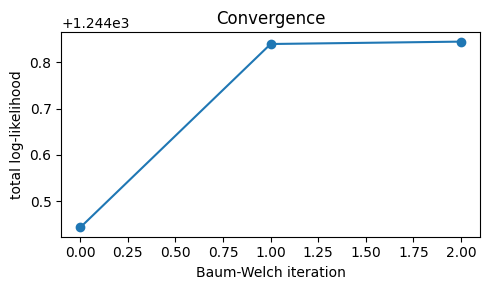

state -> activity: {0: 'standing', 1: 'walking', 2: 'jumping', 3: 'still'}


In [8]:
hmm = GaussianHMM(len(ACTIVITIES), len(FEATURES))
hmm.init_supervised(train_seqs, train_lab)
init_model = copy.deepcopy(hmm)                    # keep for comparison
hmm.fit(train_seqs, tol=1e-4, max_iter=200)

plt.figure(figsize=(5, 3)); plt.plot(hmm.ll_history, marker='o'); plt.xlabel('Baum-Welch iteration')
plt.ylabel('total log-likelihood'); plt.title('Convergence'); plt.tight_layout(); plt.show()

# Map hidden states -> activities by majority vote on TRAIN data (guards against state drift in EM)
def state_map(model):
    cm = np.zeros((model.K, len(ACTIVITIES)), int)
    for X, y in zip(train_seqs, train_lab):
        for s, a in zip(model.viterbi(X)[0], y): cm[s, a] += 1
    return cm.argmax(1)
MAP = state_map(hmm); print('state -> activity:', {i: ACTIVITIES[m] for i, m in enumerate(MAP)})

## 6. Transition, initial and emission visualisation

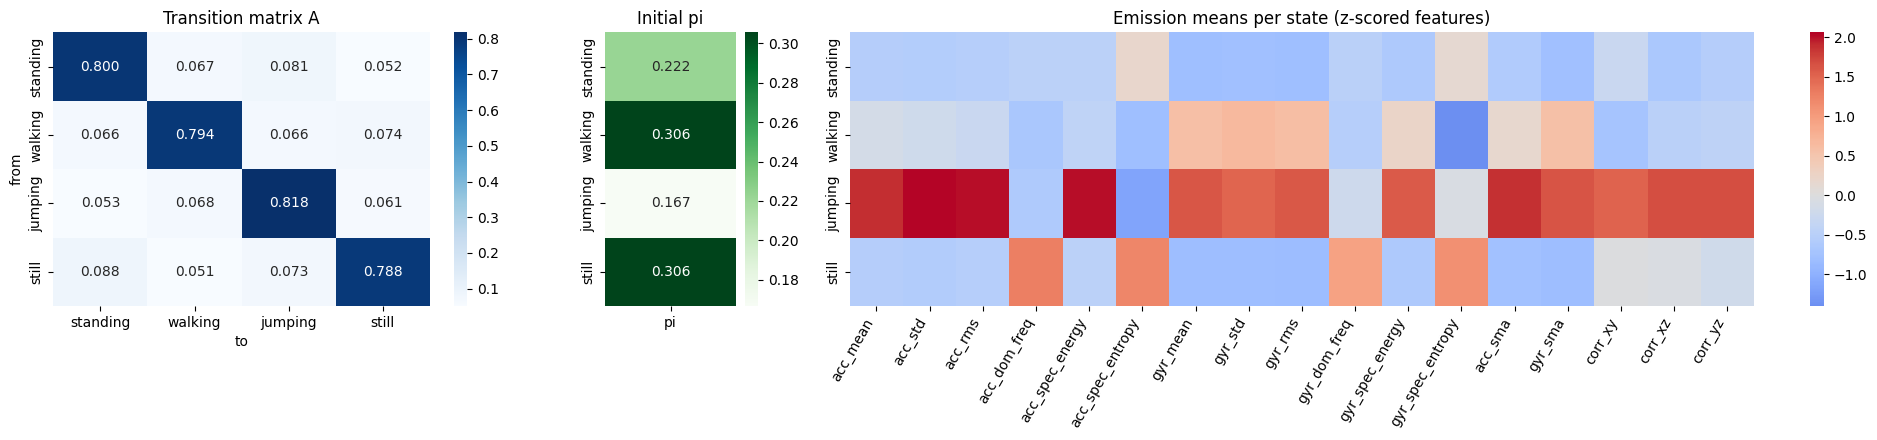

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5), gridspec_kw={'width_ratios': [1, 0.35, 2.4]})
order = np.argsort(MAP); names = [ACTIVITIES[MAP[i]] for i in order]
sns.heatmap(hmm.A[np.ix_(order, order)], annot=True, fmt='.3f', cmap='Blues', xticklabels=names, yticklabels=names, ax=ax[0])
ax[0].set_title('Transition matrix A'); ax[0].set_xlabel('to'); ax[0].set_ylabel('from')
sns.heatmap(hmm.pi[order][:, None], annot=True, fmt='.3f', cmap='Greens', yticklabels=names, xticklabels=['pi'], ax=ax[1])
ax[1].set_title('Initial pi')
sns.heatmap(hmm.mu[order], cmap='coolwarm', center=0, xticklabels=FEATURES, yticklabels=names, ax=ax[2])
ax[2].set_title('Emission means per state (z-scored features)'); plt.setp(ax[2].get_xticklabels(), rotation=60, ha='right')
plt.tight_layout(); plt.show()

## 7. Evaluation on unseen data (Viterbi decoding)


=== Supervised init only (no Baum-Welch) ===


,State (Activity),Number of Samples,Sensitivity,Specificity,Per-class Accuracy,Overall Accuracy
0,standing,28,1.0,1.0,1.0,1.0
1,walking,36,1.0,1.0,1.0,1.0
2,jumping,36,1.0,1.0,1.0,1.0
3,still,16,1.0,1.0,1.0,1.0



=== After Baum-Welch ===


,State (Activity),Number of Samples,Sensitivity,Specificity,Per-class Accuracy,Overall Accuracy
0,standing,28,1.0,1.0,1.0,1.0
1,walking,36,1.0,1.0,1.0,1.0
2,jumping,36,1.0,1.0,1.0,1.0
3,still,16,1.0,1.0,1.0,1.0


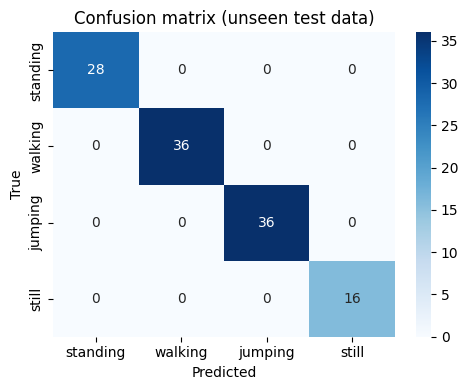

In [10]:
def decode(model, seqs, mapping):
    return [mapping[model.viterbi(X)[0]] for X in seqs]

def confusion(y, p, K):
    cm = np.zeros((K, K), int)
    for t, q in zip(y, p): cm[t, q] += 1
    return cm

def metrics_table(cm):
    N, rows = cm.sum(), []
    for i, a in enumerate(ACTIVITIES):
        TP = cm[i, i]; FN = cm[i].sum() - TP; FP = cm[:, i].sum() - TP; TN = N - TP - FN - FP
        rows.append({'State (Activity)': a, 'Number of Samples': int(cm[i].sum()),
                     'Sensitivity': TP / (TP + FN) if TP + FN else np.nan,
                     'Specificity': TN / (TN + FP) if TN + FP else np.nan,
                     'Per-class Accuracy': (TP + TN) / N,
                     'Overall Accuracy': np.trace(cm) / N})
    return pd.DataFrame(rows).round(3)

y_true = np.concatenate(test_lab)
for label, model, mp in [('Supervised init only (no Baum-Welch)', init_model, state_map(init_model)),
                         ('After Baum-Welch', hmm, MAP)]:
    p = np.concatenate(decode(model, test_seqs, mp))
    print(f'\n=== {label} ===')
    display(metrics_table(confusion(y_true, p, len(ACTIVITIES))))

y_pred = np.concatenate(decode(hmm, test_seqs, MAP))
cm = confusion(y_true, y_pred, len(ACTIVITIES))
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=ACTIVITIES, yticklabels=ACTIVITIES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (unseen test data)'); plt.tight_layout(); plt.show()

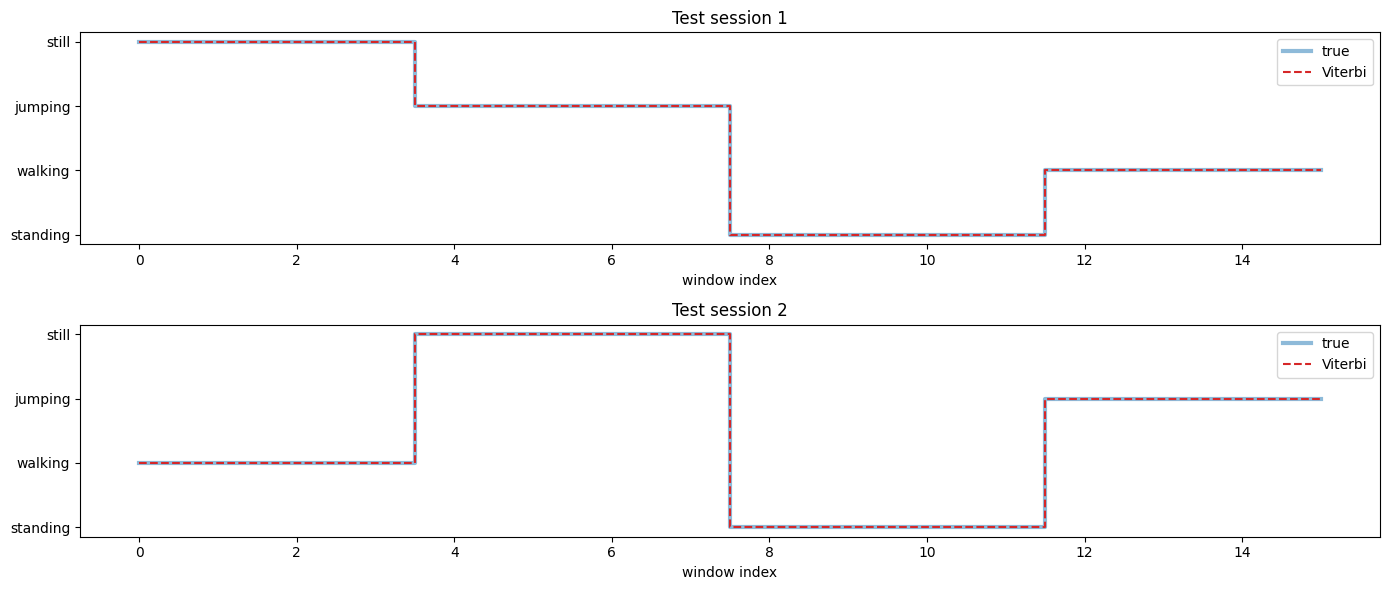

In [11]:
# Decoded sequences: true vs predicted activity for the unseen test sessions
n = min(2, len(test_seqs)); fig, axes = plt.subplots(n, 1, figsize=(14, 3 * n), squeeze=False)
preds = decode(hmm, test_seqs, MAP)
for i in range(n):
    ax = axes[i, 0]
    ax.step(range(len(test_lab[i])), test_lab[i], where='mid', label='true', lw=3, alpha=0.5)
    ax.step(range(len(preds[i])), preds[i], where='mid', label='Viterbi', ls='--', color='tab:red')
    ax.set_yticks(range(len(ACTIVITIES))); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel('window index')
    ax.set_title(f'Test session {i + 1}'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

## 8. Analysis and reflection

**Easiest and hardest activities.** All four activities were classified perfectly on the unseen test session (sensitivity, specificity and accuracy = 1.0). Jumping was the clearest: its emission means sit about 2 standard deviations above the others on accelerometer std, RMS and spectral energy. Standing and still were the closest pair, because their amplitude features are almost identical (acc_std about -0.57 vs -0.59 in z-score units). They separate mainly on spectral features: still has a higher dominant frequency and higher spectral entropy (noise-like), while standing has small, slightly more structured hand-tremor motion. Walking separates from standing on gyroscope energy and low spectral entropy (regular steps near 1.7 Hz).

**Transition probabilities.** Each activity stays in itself with probability about 0.79-0.82, and moves to each other activity with about 0.05-0.09. The strong diagonal is realistic, since a person stays in an activity across consecutive 2 s windows. The off-diagonal values are close to uniform because I stitched separate recordings together into sessions, so they reflect my recording protocol and not real behaviour (for example, jumping straight to still).

**Sensor noise and sampling rate.** The phone logs at about 100 Hz and I resampled to 50 Hz, which is well above the Nyquist rate for walking and jumping (about 1.7 and 2 Hz). Still data is almost pure sensor noise (acc std about 0.001 g), so its spectral features are noise-driven but consistent. Hand tremor in standing adds small variation that separates it from still.

**Limits and improvements.** The perfect scores come from one participant, one phone and large physical differences between activities, so they should not be read as general accuracy. The test set is a separate session, but still the same person and device. Improvements: more participants and phones, more jumping data (only 7 training clips), harder activities such as sitting or running, extra features (jerk, zero-crossing rate, wavelets), and recordings with real transitions between activities.